![Banner](../../../../Images/Banner/05_geostat/08_bayesian_kriging.png)

# Bayesian Transformed Gaussian Kriging (`BayesianTransformedKriging`)

**Datasets:** Jura soil survey (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples of seven heavy metals; `jura_grid.csv` for maps) and the Meuse floodplain survey (`Data/00_shared/data_geostatistics/meuse.csv`, 155 samples of four metals)

**Targets:** ten skewed and near-symmetric metal concentrations for the survey of transformations; Jura zinc, cadmium and lead in depth

**Library:** `geolattice.geostatistics.BayesianTransformedKriging` (module `geolattice.geostatistics.kriging.bayesian_kriging`), with `BayesianKriging` for comparison

**Before this notebook:** [Bayesian kriging](05_08_02_bayesian_kriging.ipynb), whose grid posterior and Student-t mixture this model extends with a transformation parameter.

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [The Box-Cox family](#the-box-cox-family)
    - 2.2 [The transformed Gaussian model](#the-transformed-gaussian-model)
    - 2.3 [The Jacobian and the normalised transform](#the-jacobian-and-the-normalised-transform)
    - 2.4 [The posterior over λ, range and nugget](#the-posterior-over-λ-range-and-nugget)
    - 2.5 [Prediction by back-transformed draws](#prediction-by-back-transformed-draws)
    - 2.6 [Back-transformation bias](#back-transformation-bias)
    - 2.7 [The domain problem and heavy tails](#the-domain-problem-and-heavy-tails)
3. [Python Setup](#python-setup)
4. [Which Transformation Do the Data Choose?](#which-transformation-do-the-data-choose)
5. [Jura Zinc: Uncertainty About λ](#jura-zinc-uncertainty-about-λ)
    - 5.1 [Posterior of λ and the variogram parameters](#posterior-of-λ-and-the-variogram-parameters)
    - 5.2 [Validation against fixed transformations](#validation-against-fixed-transformations)
    - 5.3 [Predictive distributions at single sites](#predictive-distributions-at-single-sites)
6. [Back-Transformation: Median, Mean and the Naive Estimate](#back-transformation-median-mean-and-the-naive-estimate)
7. [Jura Cadmium: Exceedance Probabilities](#jura-cadmium-exceedance-probabilities)
8. [Jura Lead: Heavy Tails and a Cautionary Case](#jura-lead-heavy-tails-and-a-cautionary-case)
9. [Maps of Zinc](#maps-of-zinc)
10. [Summary and Conclusions](#summary-and-conclusions)
    - 10.1 [Practical guidance](#practical-guidance)
11. [References](#references)

***
## Overview

Metal concentrations, rainfall, permeability and many other variables are positive and right-skewed. Gaussian kriging and Gaussian Bayesian kriging assume a Gaussian field, so in practice the data are transformed first, usually by a log. The prediction is then back-transformed. That routine hides two decisions:

* **Which transform?** The log is a habit, not a law. Some variables need less (a square root), some more.
* **How to back-transform?** $\exp(\text{kriged log value})$ is the predictive *median*, not the mean. The mean needs a correction, and quantiles must be transformed one by one.

**Bayesian transformed Gaussian kriging** (De Oliveira, Kedem & Short, 1997) makes the transform part of the model. A Box-Cox parameter $\lambda$ joins the range and nugget on the grid of [`BayesianKriging`](05_08_02_bayesian_kriging.ipynb). The data then give a posterior over $\lambda$, and predictions are posterior predictive draws back-transformed to the original units. Every summary (median, mean, quantiles, exceedance probabilities) comes from the same draws, and the uncertainty about the transform itself is included.

| `BayesianTransformedKriging` | |
|---|---|
| parameters | `lambda_grid`, `lambda_prior`, plus everything of `BayesianKriging` (`model`, `trend`, `range_grid`, `nugget_grid`, priors) |
| fit | closed-form posterior over the (λ, range, nugget) grid; `lambda_posterior_`, `posterior_` |
| predict | Monte Carlo back-transform: `predictive_samples`, `predict` (mean, median, sd, q05, q95), `predict_quantiles`, `predict_proba` |

The notebook:

* asks ten metal datasets which transformation they choose, and relates the answer to skewness;
* studies Jura zinc, where $\lambda$ is genuinely uncertain, against fixed transforms on held-out sites;
* shows the bias of the naive back-transform;
* uses cadmium to show that the transform matters most for exceedance probabilities;
* uses lead, the most skewed metal, as a cautionary case about heavy tails;
* maps zinc on the Jura grid.

***
## Theory

### The Box-Cox family

For $z > 0$ (Box & Cox, 1964),

$$
t_\lambda(z) = \begin{cases} \dfrac{z^\lambda - 1}{\lambda} & \lambda \ne 0 \\[6pt] \log z & \lambda = 0 \end{cases}
$$

The family is continuous in $\lambda$ (the limit of $(z^\lambda - 1)/\lambda$ as $\lambda \to 0$ is $\log z$), and increasing in $z$ for every $\lambda$:

* $\lambda = 1$ leaves the data essentially as they are (a shift);
* $\lambda = 0.5$ is close to a square root;
* $\lambda = 0$ is the log;
* $\lambda < 0$ compresses the upper tail even more strongly than the log.

The more skewed the data, the smaller the $\lambda$ that makes them look Gaussian.

### The transformed Gaussian model

The model says that a transformed version of the field is Gaussian:

$$
t_\lambda\bigl(Z(\mathbf{x})\bigr) = \mathbf{f}(\mathbf{x})^\top\boldsymbol\beta + S(\mathbf{x}) + \varepsilon(\mathbf{x}),
$$

with the same Gaussian structure as in `BayesianKriging`: covariance $\sigma^2[\mathbf{R}(\phi) + \tau\mathbf{I}]$, conjugate priors on $\boldsymbol\beta$ and $\sigma^2$, and discrete priors on $\phi$, $\tau$ and now $\lambda$ (`lambda_grid`, `lambda_prior`).

### The Jacobian and the normalised transform

The likelihood of the **original** data $\mathbf{z}$ includes the Jacobian of the transform:

$$
p(\mathbf{z} \mid \lambda, \cdot) = p_{\text{Gauss}}\bigl(t_\lambda(\mathbf{z}) \mid \cdot\bigr)\, \prod_i z_i^{\lambda - 1}.
$$

Without that factor, values of $\lambda$ cannot be compared: a stronger transform shrinks the data and would always look more probable. GeoLattice uses the **normalised** Box-Cox transform,

$$
w_\lambda(z) = \frac{t_\lambda(z)}{\dot z^{\,\lambda - 1}},
\qquad
\dot z = \Bigl(\prod_i z_i\Bigr)^{1/n} \text{ (geometric mean)},
$$

whose Jacobian over the data is exactly 1 (Box & Cox, 1964). The $w$ values for different $\lambda$ are on comparable scales, and their marginal likelihoods, computed exactly as in `BayesianKriging`, can be compared directly.

### The posterior over λ, range and nugget

For every grid point $(\lambda, \phi, \tau)$, the trend and variance are integrated out in closed form, as in Bayesian kriging, which gives

$$
p(\lambda, \phi, \tau \mid \mathbf{z}) \;\propto\; p(\lambda)\, p(\phi)\, p(\tau)\; p\bigl(\mathbf{w}_\lambda \mid \phi, \tau\bigr).
$$

The marginal posterior of $\lambda$ is reported in `lambda_posterior_`, and the full grid in `posterior_`.

### Prediction by back-transformed draws

The transform is nonlinear, so the predictive distribution in original units has no closed form. `predictive_samples` draws from it:

1. pick a grid point $(\lambda, \phi, \tau)$ with its posterior probability;
2. draw $\sigma^2$, $\boldsymbol\beta$, and the Gaussian prediction $w_0$, as in `BayesianKriging` (observation scale, including the nugget);
3. back-transform: $z_0 = t_\lambda^{-1}\bigl(w_0\, \dot z^{\,\lambda - 1}\bigr)$, where $t_\lambda^{-1}(t) = (\lambda t + 1)^{1/\lambda}$, or $e^t$ for $\lambda = 0$.

The draws give the predictive median, quantiles, exceedance probabilities and, when it exists, the mean.

### Back-transformation bias

If $W_0 \sim \mathcal{N}(\mu, s^2)$ and $Z_0 = e^{W_0}$ (the log case), then

$$
\operatorname{median}(Z_0) = e^{\mu}, \qquad E[Z_0] = e^{\mu + s^2/2}.
$$

So **back-transforming the kriged log value gives the median, not the mean.** When the predictive variance is large, the mean exceeds the median by the factor $e^{s^2/2}$. That is the bias that lognormal kriging corrects analytically (Journel, 1980). For other $\lambda$ no simple formula exists. Monte Carlo draws handle every $\lambda$, and a mixture over $\lambda$, the same way.

### The domain problem and heavy tails

$t_\lambda$ maps $(0, \infty)$ onto a half-line, not the whole real line:

* for $\lambda > 0$, onto $(-1/\lambda, \infty)$;
* for $\lambda < 0$, onto $(-\infty, -1/\lambda)$.

A Gaussian $W$ puts some probability outside that range. For $\lambda > 0$, draws below $-1/\lambda$ are mapped to 0. For $\lambda < 0$, draws above $-1/\lambda$ correspond to $Z = +\infty$: the transformed-Gaussian predictive with $\lambda < 0$ has an infinitely heavy upper tail, and **its mean does not exist** (De Oliveira et al., 1997). GeoLattice returns those draws as `inf` and warns. The median and quantiles stay well defined and are the summaries to use.

***
## Python Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import BayesianKriging, BayesianTransformedKriging

warnings.filterwarnings("ignore", category=DeprecationWarning)
print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")


def crps(draws, y):
    s = np.sort(draws, axis=0)
    m = s.shape[0]
    w = (2 * np.arange(1, m + 1) - m - 1) / (m * m)
    return np.mean(np.abs(s - y).mean(0) - (w[:, None] * s).sum(0))


DATA = "../../../../Data/00_shared/data_geostatistics/"
jura = pd.read_csv(DATA + "jura_data.csv", index_col=0)
meuse = pd.read_csv(DATA + "meuse.csv")
LAMBDA_GRID = np.array([-1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0, 1.5])
NUGGET_GRID = np.array([0.0, 0.1, 0.25, 0.5, 1.0])

pygstat version: 0.3.44


***
## Which Transformation Do the Data Choose?

Each of seven Jura metals and three Meuse metals is fitted with $\lambda \in \{-1, -0.75, \dots, 1.5\}$, a uniform prior, an exponential model, 15 ranges and 5 nugget ratios. The posterior of $\lambda$ is compared with the skewness of the data.

,n,skewness,posterior mode of lambda,P(mode),posterior mean of lambda,P(lambda = 0)
data,,,,,,
Jura Ni,359,0.111,0.75,0.661,0.666,0.000
Jura Cr,359,0.297,0.75,0.719,0.683,0.000
Jura Co,359,-0.179,0.75,0.630,0.842,0.000
Jura Cd,359,1.478,0.00,0.989,-0.003,0.989
Jura Zn,359,1.493,-0.25,0.583,-0.147,0.414
Jura Cu,359,3.018,-0.25,1.000,-0.250,0.000
Jura Pb,359,3.352,-0.50,0.585,-0.604,0.000
Meuse zinc,155,1.486,-0.25,0.665,-0.329,0.011
Meuse copper,155,1.414,-0.75,0.595,-0.758,0.000


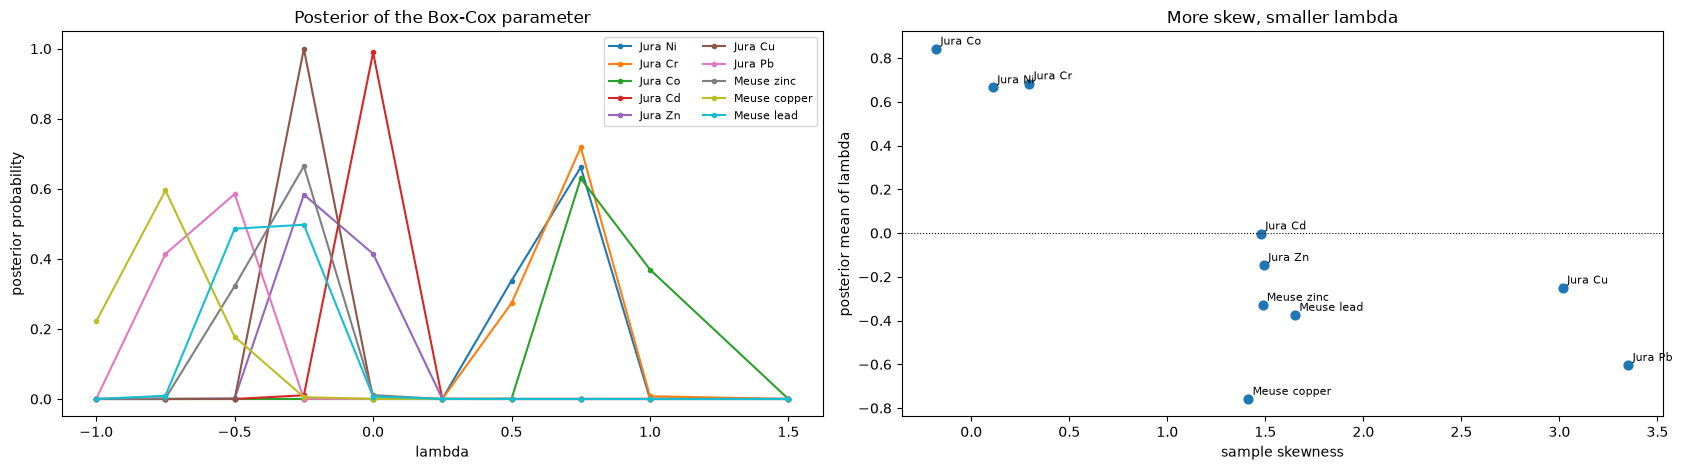

✅ [PASS] posterior lambda decreases with skewness  correlation -0.80


In [2]:
datasets = [(f"Jura {v}", jura, "Xloc", "Yloc", v) for v in ["Ni", "Cr", "Co", "Cd", "Zn", "Cu", "Pb"]] + \
           [(f"Meuse {v}", meuse, "x", "y", v) for v in ["zinc", "copper", "lead"]]
rows, lam_posts = [], {}
for name, d, xc, yc, v in datasets:
    xy_ = d[[xc, yc]].to_numpy(float)
    z_ = d[v].to_numpy(float)
    dmax = np.sqrt(((xy_[:, None] - xy_[None]) ** 2).sum(-1)).max()
    m = BayesianTransformedKriging("exponential", lambda_grid=LAMBDA_GRID, nugget_grid=NUGGET_GRID,
                                   range_grid=np.geomspace(0.01 * dmax, dmax, 15)).fit(xy_, z_)
    lp = m.lambda_posterior_
    lam_posts[name] = lp
    rows.append({"data": name, "n": len(z_), "skewness": pd.Series(z_).skew(), "posterior mode of lambda": lp.idxmax(),
                 "P(mode)": lp.max(), "posterior mean of lambda": float((lp.index.values * lp.values).sum()),
                 "P(lambda = 0)": lp.get(0.0, 0.0)})
survey = pd.DataFrame(rows).set_index("data")
display(survey.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
for name, lp in lam_posts.items():
    axes[0].plot(lp.index, lp.values, "o-", ms=3, label=name)
axes[0].set_xlabel("lambda")
axes[0].set_ylabel("posterior probability")
axes[0].set_title("Posterior of the Box-Cox parameter")
axes[0].legend(fontsize=8, ncol=2)
axes[1].scatter(survey["skewness"], survey["posterior mean of lambda"], s=40)
for name, r in survey.iterrows():
    axes[1].annotate(name, (r["skewness"], r["posterior mean of lambda"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].axhline(0, color="k", lw=0.8, ls=":")
axes[1].set_xlabel("sample skewness")
axes[1].set_ylabel("posterior mean of lambda")
axes[1].set_title("More skew, smaller lambda")
plt.tight_layout()
plt.show()
r_ = np.corrcoef(survey["skewness"], survey["posterior mean of lambda"])[0, 1]
record("posterior lambda decreases with skewness", "PASS" if r_ < -0.7 else "FAIL", f"correlation {r_:.2f}")

* **The more skewed the data, the smaller the λ** (correlation −0.80).
    * **Near-symmetric metals** (Jura Ni, Cr and Co, skewness between −0.2 and 0.3) prefer λ ≈ 0.75: a mild transform, not none.
    * **Moderate skew.** Jura cadmium (skewness 1.5) chooses the log almost certainly (P = 0.99). Jura zinc, with the same skewness, splits between −0.25 (0.58) and 0 (0.41).
    * **Strong skew.** Jura copper and lead (skewness above 3) and the three Meuse metals choose λ between −0.25 and −0.76.
* **The log is rarely the posterior mode.** Among the six skewed variables, only cadmium settles on it. The usual log transform is often reasonable, but it is a choice the data can be asked to make.

***
## Jura Zinc: Uncertainty About λ

Zinc is the case where the data do not settle on one transform. The 70/30 stratified split of the earlier Bayesian kriging notebooks is used (by land use, `random_state=42`). The model has a spherical correlation, 15 ranges from 0.05 to 4 km and the λ grid above.

In [3]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr, te = next(sss.split(jura, jura["Landuse"]))
train, test = jura.iloc[tr].reset_index(drop=True), jura.iloc[te].reset_index(drop=True)
xy, xy_test = train[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
RANGE_GRID = np.geomspace(0.05, 4.0, 15)
BT_KW = dict(model="spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID)

zn, zn_test = train["Zn"].to_numpy(float), test["Zn"].to_numpy(float)
t0 = time.perf_counter()
bt_zn = BayesianTransformedKriging(lambda_grid=LAMBDA_GRID, **BT_KW).fit(xy, zn)
print(f"posterior over {len(bt_zn.posterior_)} (lambda, range, nugget) grid points in {time.perf_counter() - t0:.2f} s")
display(bt_zn.lambda_posterior_.round(3).to_frame("P(lambda | Zn)").T)

posterior over 750 (lambda, range, nugget) grid points in 0.45 s


lambda,-1.00,-0.75,-0.50,-0.25,0.00,0.25,0.50,0.75,1.00,1.50
P(lambda | Zn),0.0,0.0,0.052,0.783,0.164,0.001,0.0,0.0,0.0,0.0


### Posterior of λ and the variogram parameters

The joint posterior of $\lambda$ and the range (summed over the nugget), and $\lambda$ against the nugget ratio. The transform and the variogram are estimated together, so the choice of $\lambda$ changes which variogram fits.

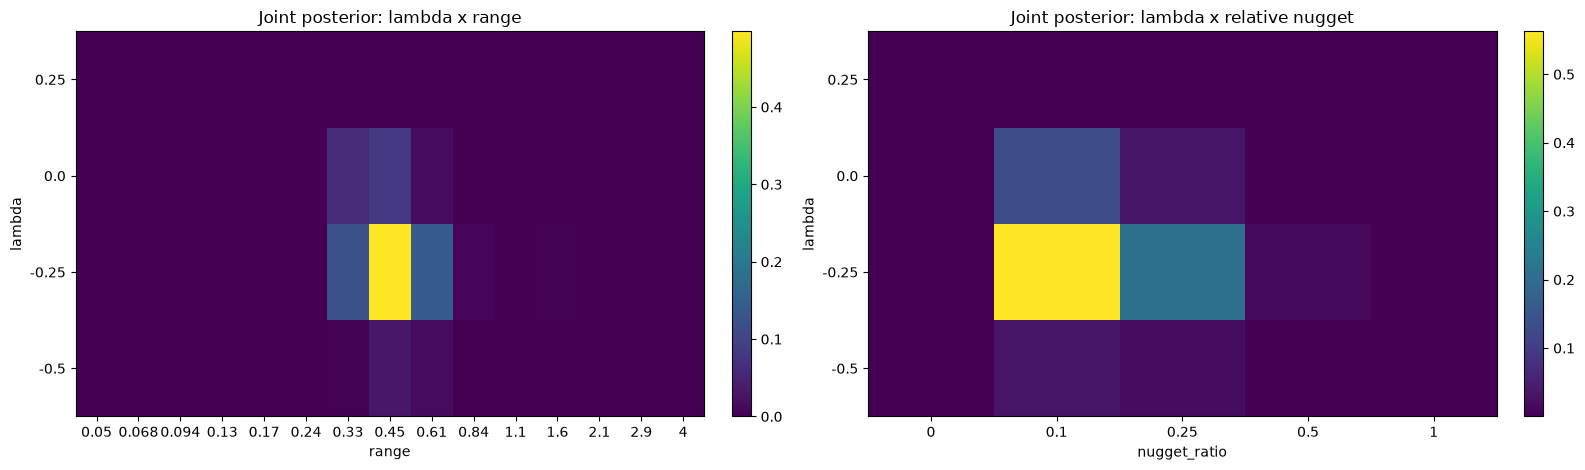

lambda = -0.50: P = 0.052; posterior mean range 0.51 km, nugget ratio 0.16
lambda = -0.25: P = 0.783; posterior mean range 0.47 km, nugget ratio 0.15
lambda = +0.00: P = 0.164; posterior mean range 0.43 km, nugget ratio 0.13


In [4]:
post = bt_zn.posterior_
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, col, title in [(axes[0], "range", "lambda x range"), (axes[1], "nugget_ratio", "lambda x relative nugget")]:
    W = post.groupby(["lambda", col]).weight.sum().unstack(col)
    W = W.loc[W.sum(1) > 1e-4]
    im = ax.imshow(W.values, aspect="auto", origin="lower", cmap="viridis")
    ax.set_yticks(range(len(W.index)), W.index)
    ax.set_xticks(range(0, len(W.columns), max(1, len(W.columns) // 8)),
                  [f"{c:.2g}" for c in W.columns[::max(1, len(W.columns) // 8)]])
    ax.set_ylabel("lambda")
    ax.set_xlabel(col)
    ax.set_title(f"Joint posterior: {title}")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
for lam in bt_zn.lambda_posterior_[bt_zn.lambda_posterior_ > 0.01].index:
    sub = post[post["lambda"] == lam]
    w = sub.weight / sub.weight.sum()
    print(f"lambda = {lam:+.2f}: P = {bt_zn.lambda_posterior_[lam]:.3f}; posterior mean range {(w * sub.range).sum():.2f} km, "
          f"nugget ratio {(w * sub.nugget_ratio).sum():.2f}")

### Validation against fixed transformations

The posterior mixture over $\lambda$ is compared with the same model with $\lambda$ **fixed** at 0 (the usual log), 0.5 (square root) and 1 (no transform), at the 108 held-out sites. Each model draws 3,000 predictive samples per site, in mg/kg.

| Metric | Meaning |
|---|---|
| RMSE / MAE of the median | point accuracy |
| coverage / width of the 90% interval | calibration and sharpness |
| CRPS | quality of the whole predictive distribution |

In [5]:
def score_bt(model, z_test, n=3000, seed=1):
    s = model.predictive_samples(xy_test, n, seed=seed)
    med = np.median(s, 0)
    lo, hi = np.quantile(s, [0.05, 0.95], axis=0)
    return {"RMSE (median)": np.sqrt(np.mean((med - z_test) ** 2)), "MAE (median)": np.mean(np.abs(med - z_test)),
            "coverage 90%": np.mean((z_test >= lo) & (z_test <= hi)), "width 90%": np.mean(hi - lo),
            "CRPS": crps(s, z_test)}, s


rows, zn_draws = [], {}
for label, lg in [("posterior over lambda", LAMBDA_GRID), ("lambda = 0 (log)", [0.0]),
                  ("lambda = 0.5 (sqrt)", [0.5]), ("lambda = 1 (none)", [1.0])]:
    m = bt_zn if len(lg) > 1 else BayesianTransformedKriging(lambda_grid=lg, **BT_KW).fit(xy, zn)
    sc, s = score_bt(m, zn_test)
    rows.append({"model": label, **sc})
    zn_draws[label] = s
zn_val = pd.DataFrame(rows).set_index("model")
display(zn_val.round(3))
best = zn_val["CRPS"].idxmin()
record("lambda posterior within 3% of the best fixed transform on CRPS",
       "PASS" if zn_val.loc["posterior over lambda", "CRPS"] <= 1.03 * zn_val["CRPS"].min() else "FAIL",
       f"posterior {zn_val.loc['posterior over lambda', 'CRPS']:.2f}, best {best} {zn_val['CRPS'].min():.2f}")

,RMSE (median),MAE (median),coverage 90%,width 90%,CRPS
model,,,,,
posterior over lambda,23.496,16.952,0.889,71.456,12.085
lambda = 0 (log),23.131,16.757,0.898,70.638,11.952
lambda = 0.5 (sqrt),22.594,16.331,0.898,73.413,11.847
lambda = 1 (none),22.506,16.223,0.935,83.836,12.133


✅ [PASS] lambda posterior within 3% of the best fixed transform on CRPS  posterior 12.08, best lambda = 0.5 (sqrt) 11.85


* **For point prediction, the transform hardly matters.** RMSE of the predictive median is 22.5-23.5 mg/kg for every model, and CRPS is within 2%: the square root is best (11.85), then the log (11.95), the λ posterior (12.08) and no transform (12.13).
* **The difference is in the intervals.** Without a transform they are wider (83.8 against 70.6-73.4 mg/kg); they over-cover (0.94) because they are symmetric while the data are skewed.
* **The held-out sites slightly prefer less transformation** than the marginal likelihood does (square root rather than −0.25). The λ posterior, which mixes −0.25, 0 and −0.5, is close to the best fixed choice without knowing it in advance.
* **The variogram is stable across λ.** Ranges are 0.43-0.51 km and nugget ratios 0.13-0.16 for the three λ values with weight.

### Predictive distributions at single sites

Histograms of the predictive draws at three held-out sites (low, median and high predicted zinc) under the λ posterior and with no transform. The transform changes the **shape** of each site's distribution, especially its upper tail.

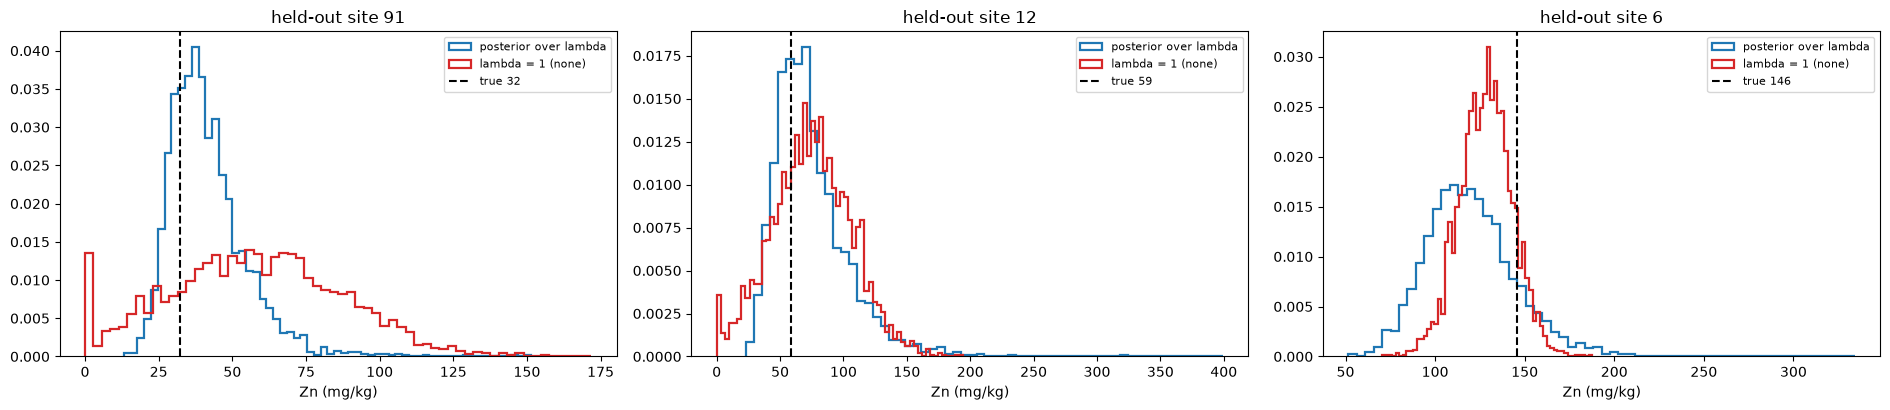

In [6]:
med_post = np.median(zn_draws["posterior over lambda"], 0)
sites = np.argsort(med_post)[[5, len(med_post) // 2, len(med_post) - 3]]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
for ax, i in zip(axes, sites):
    for label, c in [("posterior over lambda", "tab:blue"), ("lambda = 1 (none)", "tab:red")]:
        ax.hist(zn_draws[label][:, i], bins=60, density=True, histtype="step", lw=1.6, color=c, label=label)
    ax.axvline(zn_test[i], color="k", ls="--", label=f"true {zn_test[i]:.0f}")
    ax.set_xlabel("Zn (mg/kg)")
    ax.set_title(f"held-out site {i}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

***
## Back-Transformation: Median, Mean and the Naive Estimate

The common shortcut is to krige $\log z$ and report $\exp(\hat w)$. Section 2.6 says that this is the predictive **median**. Here are three estimates at the held-out zinc sites:

* the **naive** back-transform: $\exp$ of the Bayesian kriging predictive mean of $\log$ Zn;
* the predictive **median** of the λ = 0 draws;
* the predictive **mean** of the λ = 0 draws.

Their averages over the test sites are compared with the average observed zinc, and the gap is related to the lognormal factor $e^{s^2/2}$.

In [7]:
bk_log = BayesianKriging("spherical", range_grid=RANGE_GRID, nugget_grid=NUGGET_GRID).fit(xy, np.log(zn))
mu_log, sd_log = bk_log.predict(xy_test, return_std=True, signal=False)
s0 = zn_draws["lambda = 0 (log)"]
comp = pd.DataFrame({
    "average over test sites (mg/kg)": [np.exp(mu_log).mean(), np.median(s0, 0).mean(), s0.mean(0).mean(),
                                        (np.exp(mu_log + sd_log ** 2 / 2)).mean(), zn_test.mean()]},
    index=["naive exp(mean of log)", "predictive median (draws)", "predictive mean (draws)",
           "lognormal formula exp(mu + s^2/2)", "observed zinc"])
display(comp.round(2))
print(f"mean predictive sd of log Zn: {sd_log.mean():.3f}  ->  e^(s^2/2) = {np.exp(sd_log.mean() ** 2 / 2):.3f}")
gap = (s0.mean(0).mean() - zn_test.mean()) / zn_test.mean()
gap_naive = (np.exp(mu_log).mean() - zn_test.mean()) / zn_test.mean()
record("predictive mean closer to the observed average than the naive back-transform",
       "PASS" if abs(gap) < abs(gap_naive) else "FAIL", f"naive {gap_naive:+.1%}, mean of draws {gap:+.1%}")

,average over test sites (mg/kg)
naive exp(mean of log),69.54
predictive median (draws),69.51
predictive mean (draws),72.84
lognormal formula exp(mu + s^2/2),72.93
observed zinc,74.09


mean predictive sd of log Zn: 0.295  ->  e^(s^2/2) = 1.044
✅ [PASS] predictive mean closer to the observed average than the naive back-transform  naive -6.1%, mean of draws -1.7%


* **The naive back-transform is the median.** $\exp(\text{mean of log})$ averages 69.5 mg/kg, exactly the median of the λ = 0 draws (69.5).
* **The mean is higher.** The predictive mean is 72.8 mg/kg, matching the lognormal formula $e^{\mu + s^2/2}$ (72.9). With a predictive sd of about 0.30 on the log scale, the factor $e^{s^2/2}$ is 1.044.
* **Against the observed average** (74.1 mg/kg), the naive estimate is 6.1% low, and the mean of the draws is 1.7% low.

The draws give the right answer for any λ, including mixtures, where no closed-form correction exists. Report the median as a robust typical value and the mean when totals or averages matter, but never present the naive back-transform as a mean.

***
## Jura Cadmium: Exceedance Probabilities

For a decision against a threshold, the tail of the predictive distribution matters, not its centre. Cadmium against the Swiss guide value of 0.8 mg/kg: about 60% of the samples exceed it, so the threshold sits in the body of the distribution, where the shape of the predictive distribution matters. The λ posterior is compared with fixed transforms by the Brier score of $P(\text{Cd} > 0.8)$ at the held-out sites, and by its reliability (calibration curve).

P(lambda | Cd): {0.0: 0.967, 0.25: 0.03}


,Brier (Cd > 0.8),log score,CRPS
model,,,
posterior over lambda,0.1716,0.5042,0.3647
lambda = 0 (log),0.1715,0.5036,0.3648
lambda = 1 (none),0.2019,0.5772,0.3929


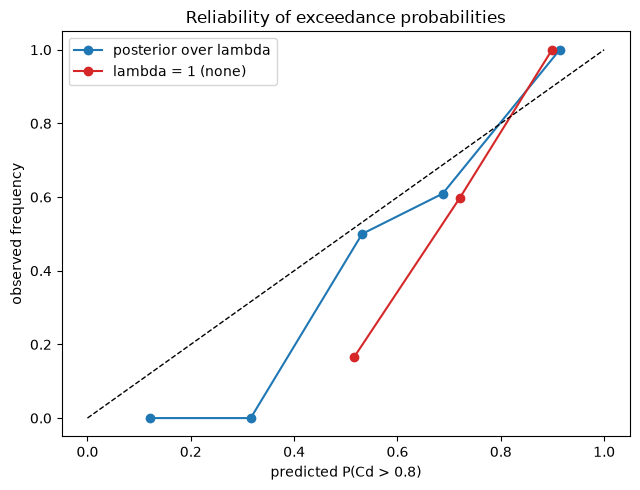

✅ [PASS] transformed model beats no transform on Brier (Cd > 0.8)  0.202 -> 0.172


In [8]:
cd, cd_test = train["Cd"].to_numpy(float), test["Cd"].to_numpy(float)
o = (cd_test > 0.8).astype(float)
rows, probs = [], {}
bt_cd = BayesianTransformedKriging(lambda_grid=LAMBDA_GRID, **BT_KW).fit(xy, cd)
print("P(lambda | Cd):", bt_cd.lambda_posterior_[bt_cd.lambda_posterior_ > 0.005].round(3).to_dict())
for label, lg in [("posterior over lambda", LAMBDA_GRID), ("lambda = 0 (log)", [0.0]), ("lambda = 1 (none)", [1.0])]:
    m = bt_cd if len(lg) > 1 else BayesianTransformedKriging(lambda_grid=lg, **BT_KW).fit(xy, cd)
    s = m.predictive_samples(xy_test, 3000, seed=2)
    p = (s > 0.8).mean(0)
    probs[label] = p
    rows.append({"model": label, "Brier (Cd > 0.8)": np.mean((p - o) ** 2),
                 "log score": -np.mean(o * np.log(np.clip(p, 1e-3, 1)) + (1 - o) * np.log(np.clip(1 - p, 1e-3, 1))),
                 "CRPS": crps(s, cd_test)})
cd_tab = pd.DataFrame(rows).set_index("model")
display(cd_tab.round(4))

bins = np.linspace(0, 1, 6)
fig, ax = plt.subplots(figsize=(6.5, 5))
for label, c in [("posterior over lambda", "tab:blue"), ("lambda = 1 (none)", "tab:red")]:
    idx = np.digitize(probs[label], bins[1:-1])
    xs = [probs[label][idx == k].mean() for k in range(5) if (idx == k).sum() >= 5]
    ys = [o[idx == k].mean() for k in range(5) if (idx == k).sum() >= 5]
    ax.plot(xs, ys, "o-", c=c, label=label)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("predicted P(Cd > 0.8)")
ax.set_ylabel("observed frequency")
ax.set_title("Reliability of exceedance probabilities")
ax.legend()
plt.tight_layout()
plt.show()
record("transformed model beats no transform on Brier (Cd > 0.8)",
       "PASS" if cd_tab.loc["posterior over lambda", "Brier (Cd > 0.8)"] < cd_tab.loc["lambda = 1 (none)", "Brier (Cd > 0.8)"] else "FAIL",
       f"{cd_tab.loc['lambda = 1 (none)', 'Brier (Cd > 0.8)']:.3f} -> {cd_tab.loc['posterior over lambda', 'Brier (Cd > 0.8)']:.3f}")

* **For a threshold, the transform matters.** The λ posterior (97% on the log) and the fixed log give the same exceedance probabilities: Brier 0.172 and log score 0.504. Without a transform, the Brier score is 15% worse (0.202) and the log score 0.577. CRPS is also worse (0.393 against 0.365).
* **Why.** A symmetric predictive distribution puts too much probability below the threshold for sites predicted near it, and too little in the long upper tail. The reliability curve shows the untransformed probabilities drifting off the diagonal.

***
## Jura Lead: Heavy Tails and a Cautionary Case

Lead is the most skewed Jura metal, with a few very high values from local contamination. The survey above put its λ posterior below 0. Two things to check:

* what happens to the predictive draws when $\lambda < 0$ (Section 2.7);
* whether the λ preferred by the marginal likelihood also predicts best.

In [9]:
pb, pb_test = train["Pb"].to_numpy(float), test["Pb"].to_numpy(float)
print(f"Pb: skewness {pd.Series(pb).skew():.2f}, max {pb.max():.0f} mg/kg, median {np.median(pb):.0f}")
bt_pb = BayesianTransformedKriging(lambda_grid=LAMBDA_GRID, **BT_KW).fit(xy, pb)
print("P(lambda | Pb):", bt_pb.lambda_posterior_[bt_pb.lambda_posterior_ > 0.005].round(3).to_dict())
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    s_pb = bt_pb.predictive_samples(xy_test, 3000, seed=3)
for w in caught:
    print("warning:", w.message)
finite = np.isfinite(s_pb)
print(f"infinite draws: {np.mean(~finite):.3%};  largest finite draw: {s_pb[finite].max():,.0f} mg/kg")
print(f"'mean' of the draws at the test sites: {np.mean(s_pb, 0).mean()}  (undefined for lambda < 0)")

rows = []
for label, lg in [("posterior over lambda", LAMBDA_GRID), ("lambda = -0.5", [-0.5]), ("lambda = 0 (log)", [0.0]),
                  ("lambda = 0.5", [0.5]), ("lambda = 1 (none)", [1.0])]:
    m = bt_pb if len(lg) > 1 else BayesianTransformedKriging(lambda_grid=lg, **BT_KW).fit(xy, pb)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        s = m.predictive_samples(xy_test, 3000, seed=3)
    med = np.median(s, 0)
    lo, hi = np.quantile(s, [0.05, 0.95], axis=0)
    rows.append({"model": label, "MAE (median)": np.mean(np.abs(med - pb_test)),
                 "coverage 90%": np.mean((pb_test >= lo) & (pb_test <= hi)), "median width 90%": np.median(hi - lo),
                 "max finite draw": np.max(s[np.isfinite(s)])})
pb_tab = pd.DataFrame(rows).set_index("model")
display(pb_tab.round(3))

Pb: skewness 3.41, max 300 mg/kg, median 46


P(lambda | Pb): {-1.0: 0.153, -0.75: 0.819, -0.5: 0.028}


infinite draws: 0.065%;  largest finite draw: 410,824 mg/kg
'mean' of the draws at the test sites: inf  (undefined for lambda < 0)


,MAE (median),coverage 90%,median width 90%,max finite draw
model,,,,
posterior over lambda,15.315,0.787,55.554,410823.700
lambda = -0.5,15.427,0.815,55.726,6206.729
lambda = 0 (log),15.702,0.852,60.059,506.851
lambda = 0.5,15.913,0.907,78.158,269.347
lambda = 1 (none),16.307,0.954,106.339,215.931


* **The likelihood wants a very strong transform.** It puts λ at −0.75 (0.82) or −1 (0.15). With λ < 0, the back-transformed predictive has an infinite upper tail: 0.065% of the draws are infinite, the largest finite draw is 410,824 mg/kg, against a data maximum of 300, and the "mean" is infinite. GeoLattice warns, and the median and quantiles are the only usable summaries.
* **The data-chosen λ predicts the median best but is poorly calibrated.** It has the best MAE of the median (15.3 mg/kg), but its 90% intervals cover only 79% of the held-out values. Coverage rises steadily with λ: 0.82 at −0.5, 0.85 for the log, 0.91 at 0.5 and 0.95 without a transform. The likelihood chooses the λ that makes the training data, dominated by a few contaminated hot spots, most Gaussian. That transform squeezes the bulk of the distribution, so the intervals around typical sites come out too narrow.
* **The lesson.** The marginal likelihood is a good guide, not an oracle. When a few extreme values drive λ below 0:
    * check calibration on held-out data;
    * consider restricting the grid to λ ≥ 0 (or using the log);
    * or treat the hot spots separately, for example with an indicator or a mixture model.

***
## Maps of Zinc

The zinc model with the λ posterior is used on a 100 m version of the Jura grid (1,540 nodes). Each node's 2,000 back-transformed predictive draws give:

* the median;
* the mean;
* the width of the 90% interval;
* the probability of exceeding 100 mg/kg, about the 80th percentile of the data.

2,000 draws at 1540 nodes in 0.8 s


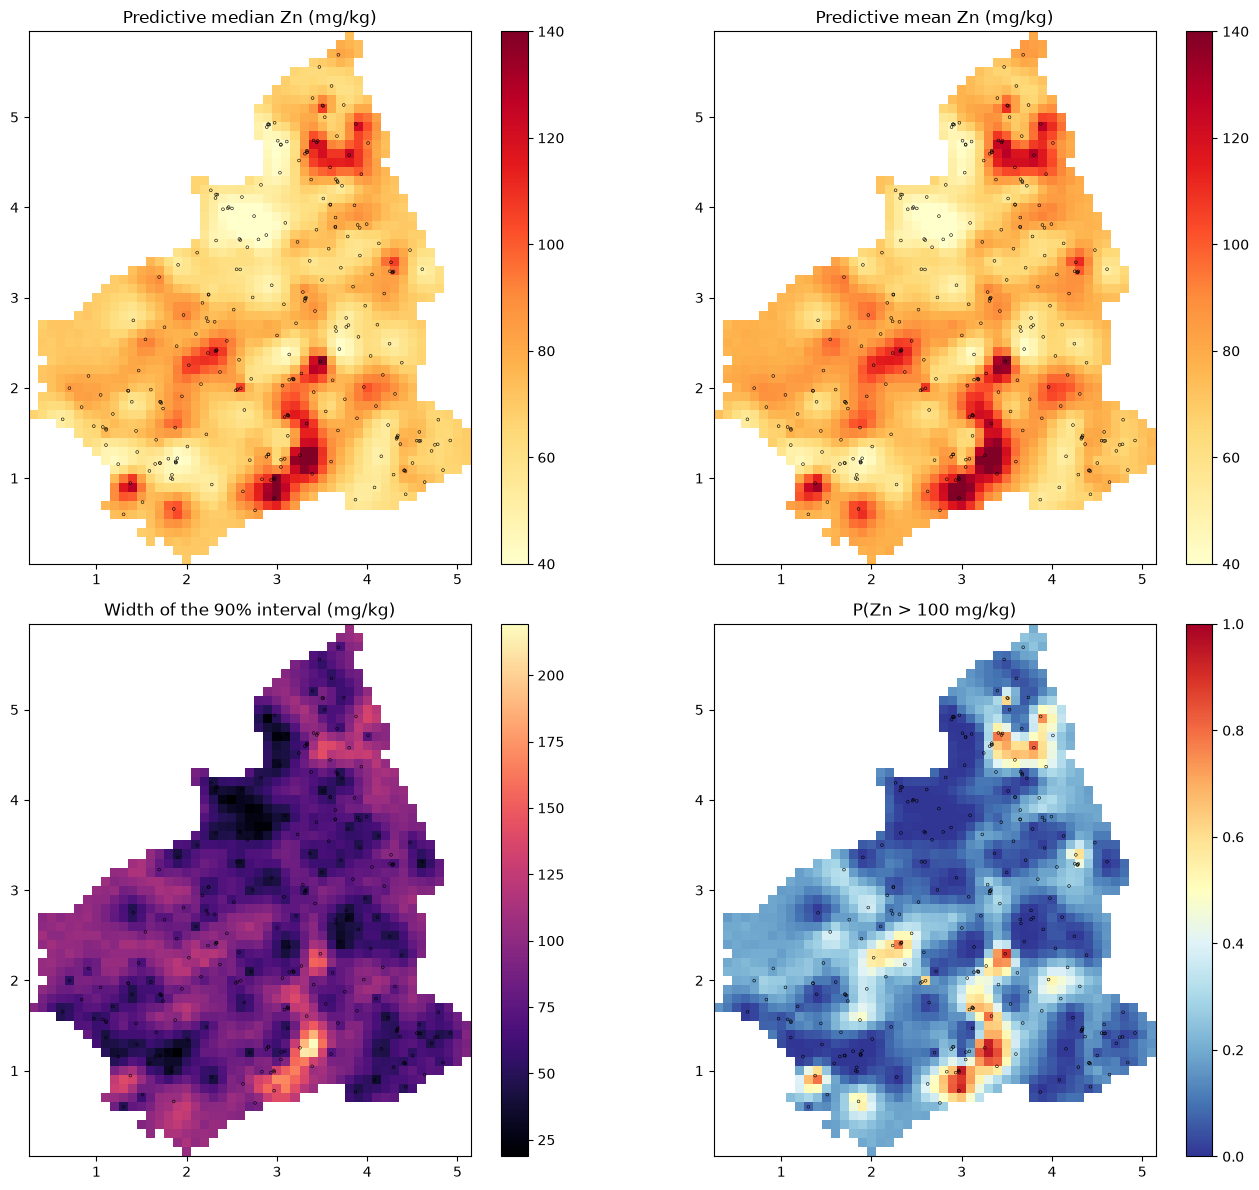

mean / median across nodes: 1.066


In [10]:
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
g = grid_df[["Xloc", "Yloc"]].to_numpy(float)
i50 = np.rint((g[:, 0] - g[:, 0].min()) / 0.05).astype(int)
j50 = np.rint((g[:, 1] - g[:, 1].min()) / 0.05).astype(int)
grid = g[(i50 % 2 == 0) & (j50 % 2 == 0)]
gi = np.rint((grid[:, 0] - grid[:, 0].min()) / 0.1).astype(int)
gj = np.rint((grid[:, 1] - grid[:, 1].min()) / 0.1).astype(int)
EXT = [grid[:, 0].min() - 0.05, grid[:, 0].max() + 0.05, grid[:, 1].min() - 0.05, grid[:, 1].max() + 0.05]

t0 = time.perf_counter()
sg = bt_zn.predictive_samples(grid, 2000, seed=4)
print(f"2,000 draws at {len(grid)} nodes in {time.perf_counter() - t0:.1f} s")
layers = [(np.median(sg, 0), "Predictive median Zn (mg/kg)", "YlOrRd", (40, 140)),
          (sg.mean(0), "Predictive mean Zn (mg/kg)", "YlOrRd", (40, 140)),
          (np.diff(np.quantile(sg, [0.05, 0.95], axis=0), axis=0)[0], "Width of the 90% interval (mg/kg)", "magma", (None, None)),
          ((sg > 100).mean(0), "P(Zn > 100 mg/kg)", "RdYlBu_r", (0, 1))]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (v, title, cm, (lo_, hi_)) in zip(axes.flat, layers):
    img = np.full((gj.max() + 1, gi.max() + 1), np.nan)
    img[gj, gi] = v
    im = ax.imshow(img, origin="lower", extent=EXT, cmap=cm, vmin=lo_, vmax=hi_, interpolation="nearest")
    ax.scatter(xy[:, 0], xy[:, 1], s=4, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
print(f"mean / median across nodes: {(sg.mean(0) / np.median(sg, 0)).mean():.3f}")

* **The maps come from the same draws** (0.8 s for 1,540 nodes), so median, mean, interval width and exceedance probability are mutually consistent.
* **Mean against median.** The mean exceeds the median by 6.6% on average, more where the predictive is wide (far from samples).
* **Intervals.** Their width is largest where predicted zinc is high: on the original scale, a skewed variable's uncertainty grows with its level, which a log-type transform builds in automatically.
* **Exceedance.** The probability map of zinc above 100 mg/kg picks out the high-zinc areas, with graded confidence in between.

***
## Summary and Conclusions

In [11]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,posterior lambda decreases with skewness,PASS,correlation -0.80
1,lambda posterior within 3% of the best fixed t...,PASS,"posterior 12.08, best lambda = 0.5 (sqrt) 11.85"
2,predictive mean closer to the observed average...,PASS,"naive -6.1%, mean of draws -1.7%"
3,transformed model beats no transform on Brier ...,PASS,0.202 -> 0.172


- **Bayesian transformed Gaussian kriging** puts the Box-Cox λ on the posterior grid. The normalised transform makes marginal likelihoods comparable across λ, and back-transformed predictive draws give every summary in original units, including the uncertainty about λ.
- **Across ten metal datasets**, λ fell with skewness (correlation −0.80): about 0.75 for near-symmetric metals, the log for Jura cadmium, and −0.25 to −0.76 for the most skewed. The log was the clear choice for only one of the six skewed variables.
- **For Jura zinc**, point predictions barely depended on the transform (CRPS within 2%), but untransformed intervals were 17% wider. The λ posterior was close to the best fixed choice.
- **The naive back-transform** exp(kriged log) is the median, 6% below the observed mean for zinc. The mean of the draws (−1.7%) and the lognormal formula agreed.
- **For exceedance probabilities**, the transform matters: for cadmium against 0.8 mg/kg, no transform gave a 15% worse Brier score than the log.
- **For lead**, the most skewed metal, the likelihood chose λ ≈ −0.75. That gives infinite predictive means, absurd extreme draws and 90% intervals covering only 79% of held-out values. Check calibration, and restrict λ or model outliers when a few extremes drive the transform.

### Practical guidance

| Situation | Choice |
|---|---|
| Positive, skewed data | `BayesianTransformedKriging` with a λ grid from about −1 to 1.5; read `lambda_posterior_` |
| λ posterior concentrated near 0 | a log model (`BayesianKriging` on log z) gives the same predictions more cheaply |
| λ uncertain | keep the mixture: it propagates the transform uncertainty into every summary |
| Decisions against a threshold | exceedance probabilities from the draws (`predict_proba`); the transform matters most here |
| Reporting a "prediction" | predictive median (robust) or mean (finite only for λ ≥ 0); never exp(kriged log) as the mean |
| λ < 0 or a few extreme values | summarize with medians and quantiles; check held-out calibration; consider restricting the λ grid or modelling the outliers separately |

***
## References

| Reference | Used for |
|---|---|
| Box, G.E.P. & Cox, D.R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society B* 26, 211-252. | Box-Cox transform, normalised transform |
| De Oliveira, V., Kedem, B. & Short, D.A. (1997). Bayesian prediction of transformed Gaussian random fields. *Journal of the American Statistical Association* 92, 1422-1433. | Bayesian transformed Gaussian kriging |
| Christensen, O.F., Diggle, P.J. & Ribeiro, P.J. (2001). Analysing positive-valued spatial data: the transformed Gaussian model. In Monestiez, P. et al. (eds.), *geoENV III*, 287-298. Kluwer. | Transformed Gaussian model in practice |
| Journel, A.G. (1980). The lognormal approach to predicting local distributions of selective mining unit grades. *Mathematical Geology* 12, 285-303. | Lognormal back-transformation bias |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | Bayesian prediction, transformed models |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura data |
| Pebesma, E.J. (2004). Multivariable geostatistics in S: the gstat package. *Computers & Geosciences* 30, 683-691. | Meuse data |
| Gneiting, T. & Raftery, A.E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association* 102, 359-378. | CRPS, Brier and log scores |